## Project Objective

The objective of this project is to predict concrete compressive strength using information about the concrete mixture and curing age.

This is a supervised regression problem because the target variable, compressive strength, is continuous.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
!pip install -U ucimlrepo


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: C:\Users\kahau\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [3]:
%pip install -U ucimlrepo

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Program Files\Python39\python.exe -m pip install --upgrade pip' command.


In [4]:
from ucimlrepo import fetch_ucirepo

# Retrieve dataset 165 from the UCI repository
concrete_dataset = fetch_ucirepo(id=165)

# Complete dataset: features and target together
df_api = concrete_dataset.data.original.copy()

print(df_api.shape)
df_api.head()

(1030, 9)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
df_concrete=df_api

In [6]:
df_concrete.shape

(1030, 9)

In [7]:
df_concrete.columns

Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age',
       'Concrete compressive strength'],
      dtype='object')

In [8]:
def normalize_text(text):
    if pd.isna(text):
        return text

    if not isinstance(text, str):
        return text

    return text.lower().strip().replace(" ", "_")


In [9]:
df_concrete.columns = [
    normalize_text(column)
    for column in df_concrete.columns
]

In [10]:
df_concrete.columns

Index(['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
       'coarse_aggregate', 'fine_aggregate', 'age',
       'concrete_compressive_strength'],
      dtype='object')

In [11]:
df_concrete.dtypes


cement                           float64
blast_furnace_slag               float64
fly_ash                          float64
water                            float64
superplasticizer                 float64
coarse_aggregate                 float64
fine_aggregate                   float64
age                                int64
concrete_compressive_strength    float64
dtype: object

In [12]:
df_api.dtypes

cement                           float64
blast_furnace_slag               float64
fly_ash                          float64
water                            float64
superplasticizer                 float64
coarse_aggregate                 float64
fine_aggregate                   float64
age                                int64
concrete_compressive_strength    float64
dtype: object

In [13]:
df_concrete.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [14]:
df_concrete.isnull().sum()

cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64

In [15]:
df_concrete.rename(
    columns={
        "blast_furnace_slag_(component_2)(kg_in_a_m^3_mixture)": "blast_furnace_slag"
    },
    inplace=True
)

In [16]:
zero_percentage = (
    df_concrete["blast_furnace_slag"].eq(0).mean() * 100
)

print(f"Zero values: {zero_percentage}")
print(f"Percentage zero: {zero_percentage:.1f}%")

Zero values: 45.728155339805824
Percentage zero: 45.7%


In [17]:
missing_summary = pd.DataFrame({
    "missing_count": df_concrete.isna().sum(),
    "missing_percentage": df_concrete.isna().mean() * 100
})

missing_summary

,missing_count,missing_percentage
cement,0,0.0
blast_furnace_slag,0,0.0
fly_ash,0,0.0
water,0,0.0
superplasticizer,0,0.0
coarse_aggregate,0,0.0
fine_aggregate,0,0.0
age,0,0.0
concrete_compressive_strength,0,0.0


In [18]:
duplicate_count = df_concrete.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 25


In [19]:
df_concrete[df_concrete.duplicated(keep=False)].sort_values(
    by=list(df_concrete.columns)
)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30


In [20]:
target_column = "concrete_compressive_strength"

feature_columns = [
    column
    for column in df_concrete.columns
    if column != target_column
]

In [21]:
exact_duplicate_count = df_concrete.duplicated().sum()

print(f"Exact duplicate rows: {exact_duplicate_count}")

Exact duplicate rows: 25


In [22]:
exact_duplicate_rows = (
    df_concrete[
        df_concrete.duplicated(keep=False)
    ]
    .sort_values(by=list(df_concrete.columns))
)

exact_duplicate_rows

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.69
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30


In [23]:
exact_duplicate_groups = (
    df_concrete
    .groupby(list(df_concrete.columns))
    .size()
    .reset_index(name="occurrence_count")
    .query("occurrence_count > 1")
    .sort_values(
        by="occurrence_count",
        ascending=False
    )
)

exact_duplicate_groups

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength,occurrence_count
786,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30,4
790,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,77.30,4
789,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30,4
791,362.6,189.0,0.0,164.9,11.6,944.7,755.8,91,79.30,4
788,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90,3
899,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20,3
898,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40,3
901,425.0,106.3,0.0,153.5,16.5,852.1,887.1,56,64.30,3
900,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29,3
902,425.0,106.3,0.0,153.5,16.5,852.1,887.1,91,65.20,3


In [24]:
repeated_input_summary = (
    df_concrete
    .groupby(feature_columns)
    .agg(
        number_of_rows=(
            target_column,
            "size"
        ),
        unique_strength_values=(
            target_column,
            "nunique"
        ),
        minimum_strength=(
            target_column,
            "min"
        ),
        maximum_strength=(
            target_column,
            "max"
        ),
        mean_strength=(
            target_column,
            "mean"
        ),
        strength_standard_deviation=(
            target_column,
            "std"
        )
    )
    .query("number_of_rows > 1")
    .sort_values(
        by="number_of_rows",
        ascending=False
    )
)

repeated_input_summary

number_of_rows  \
cement blast_furnace_slag fly_ash water superplasticizer coarse_aggregate fine_aggregate age                   
362.6  189.0              0.0     164.9 11.6             944.7            755.8          56                4   
                                                                                         3                 4   
                                                                                         7                 4   
                                                                                         91                4   
                                                                                         28                4   
425.0  106.3              0.0     153.5 16.5             852.1            887.1          56                3   
446.0  24.0               79.0    162.0 11.6             967.0            712.0          7                 3   
                                                                                         3                 3   
425.0  106.3              0.0     153.5 16.5             852.1            887.1          3                 3   
                                                                                         28                3   
                                                                                         7                 3   
446.0  24.0               79.0    162.0 11.6             967.0            712.0          28                3   
                                                                                         56                3   
425.0  106.3              0.0     153.5 16.5             852.1            887.1          91                3   
252.0  0.0                0.0     185.0 0.0              1111.0           784.0          28                2   
359.0  19.0               141.0   154.0 10.9             942.0            801.0          7                 2   
                                                                                         3                 2   
                                                                                         56                2   
                                                                                         28                2   

                                                                                              unique_strength_values  \
cement blast_furnace_slag fly_ash water superplasticizer coarse_aggregate fine_aggregate age                           
362.6  189.0              0.0     164.9 11.6             944.7            755.8          56                        1   
                                                                                         3                         1   
                                                                                         7                         2   
                                                                                         91                        1   
                                                                                         28                        1   
425.0  106.3              0.0     153.5 16.5             852.1            887.1          56                        1   
446.0  24.0               79.0    162.0 11.6             967.0            712.0          7                         3   
                                                                                         3                         3   
425.0  106.3              0.0     153.5 16.5             852.1            887.1          3                         1   
                                                                                         28                        1   
                                                                                         7                         1   
446.0  24.0               79.0    162.0 11.6             967.0            712.0          28                        3   
                                                             

In [25]:
rows_before = len(df_concrete)

df_concrete = (
    df_concrete
    .drop_duplicates()
    .reset_index(drop=True)
)

rows_after = len(df_concrete)

print(f"Rows before: {rows_before}")
print(f"Rows removed: {rows_before - rows_after}")
print(f"Rows remaining: {rows_after}")

Rows before: 1030
Rows removed: 25
Rows remaining: 1005


In [26]:
df_concrete.head(20)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29


In [27]:
remaining_duplicates = df_concrete[
    df_concrete.duplicated(keep=False)
]

remaining_duplicates

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength


### Duplicate Treatment

Exact duplicate rows were removed because they contained identical predictor
values and identical compressive-strength measurements.

Repeated concrete mixtures with different curing ages or different measured
strength values were retained because they represent distinct observations.

In [28]:
# Zero values by column
zero_summary = pd.DataFrame({
    "zero_count": (df_concrete == 0).sum(),
    "zero_percentage": (df_concrete == 0).mean() * 100
})

zero_summary.sort_values("zero_percentage", ascending=False)

,zero_count,zero_percentage
fly_ash,541,53.830846
blast_furnace_slag,470,46.766169
superplasticizer,378,37.611940
cement,0,0.000000
water,0,0.000000
coarse_aggregate,0,0.000000
fine_aggregate,0,0.000000
age,0,0.000000
concrete_compressive_strength,0,0.000000


In [29]:
zero_heavy_columns = [
    "fly_ash",
    "blast_furnace_slag",
    "superplasticizer"
]

for column in zero_heavy_columns:
    nonzero_values = df_concrete.loc[
        df_concrete[column] > 0,
        column
    ]

    print(f"\n{column}")
    print(f"Nonzero rows: {len(nonzero_values)}")
    print(f"Unique nonzero values: {nonzero_values.nunique()}")
    print(nonzero_values.describe())


fly_ash
Nonzero rows: 464
Unique nonzero values: 155
count    464.000000
mean     120.288793
std       33.675470
min       24.500000
25%       97.850000
50%      121.400000
75%      141.000000
max      200.100000
Name: fly_ash, dtype: float64

blast_furnace_slag
Nonzero rows: 535
Unique nonzero values: 184
count    535.000000
mean     135.334019
std       73.344917
min       11.000000
25%       94.700000
50%      134.000000
75%      188.500000
max      359.400000
Name: blast_furnace_slag, dtype: float64

superplasticizer
Nonzero rows: 627
Unique nonzero values: 110
count    627.000000
mean       9.670494
std        4.580139
min        1.700000
25%        6.800000
50%        9.000000
75%       11.400000
max       32.200000
Name: superplasticizer, dtype: float64


In [30]:
target = "concrete_compressive_strength"

for column in zero_heavy_columns:
    comparison = (
        df_concrete
        .assign(ingredient_present=df_concrete[column] > 0)
        .groupby("ingredient_present")[target]
        .agg(["count", "mean", "median", "std"])
    )

    print(f"\nStrength comparison for {column}")
    display(comparison)


Strength comparison for fly_ash


,count,mean,median,std
ingredient_present,,,,
False,541,35.761479,34.290,17.854479
True,464,34.654461,33.745,14.234035



Strength comparison for blast_furnace_slag


,count,mean,median,std
ingredient_present,,,,
False,470,31.624830,31.35,14.748853
True,535,38.435439,37.81,16.906314



Strength comparison for superplasticizer


,count,mean,median,std
ingredient_present,,,,
False,378,29.543492,28.13,14.729716
True,627,38.690893,37.40,16.221685


### Treatment of Zero Values

Fly ash, blast furnace slag, and superplasticizer contain substantial
percentages of zero values. These zeros are meaningful because they indicate
that the ingredient was not included in a particular concrete mixture.

The rows and columns were therefore retained. The nonzero observations provide
variation that may help predict compressive strength. Ingredient-presence
indicators may be tested during feature engineering, with their usefulness
evaluated through cross-validation.

In [31]:
df_concrete.nunique().sort_values()

age                               14
superplasticizer                 111
fly_ash                          156
blast_furnace_slag               185
water                            195
cement                           278
coarse_aggregate                 284
fine_aggregate                   302
concrete_compressive_strength    845
dtype: int64

In [32]:
df_concrete.describe().T

,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.631343,104.344261,102.00,190.70,265.0,349.00,540.0
blast_furnace_slag,1005.0,72.043483,86.170807,0.00,0.00,20.0,142.50,359.4
fly_ash,1005.0,55.536318,64.207969,0.00,0.00,0.0,118.30,200.1
water,1005.0,182.075323,21.339334,121.80,166.60,185.7,192.90,247.0
superplasticizer,1005.0,6.033234,5.919967,0.00,0.00,6.1,10.00,32.2
coarse_aggregate,1005.0,974.376816,77.579667,801.00,932.00,968.0,1031.00,1145.0
fine_aggregate,1005.0,772.688259,80.340435,594.00,724.30,780.0,822.20,992.6
age,1005.0,45.856716,63.734692,1.00,7.00,28.0,56.00,365.0
concrete_compressive_strength,1005.0,35.250378,16.284815,2.33,23.52,33.8,44.87,82.6


In [33]:
print("Shape:", df_concrete.shape)
print("Missing values:", df_concrete.isna().sum().sum())
print("Exact duplicates:", df_concrete.duplicated().sum())
print("Negative values:", (df_concrete < 0).sum().sum())

Shape: (1005, 9)
Missing values: 0
Exact duplicates: 0
Negative values: 0


# Moving to basic EDA

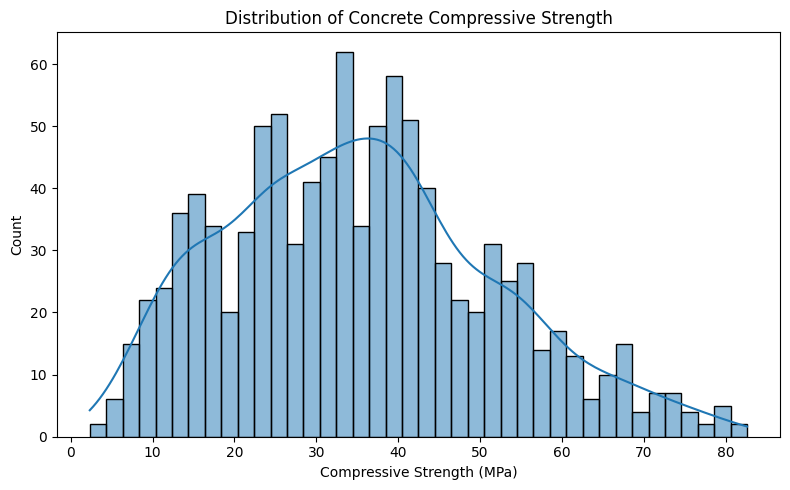

<Figure size 640x480 with 0 Axes>

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_concrete,
    x="concrete_compressive_strength",
    bins=40,
    kde=True
)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
plt.savefig(  "../plots/compressive_strength_distribution.png",
    dpi=300,
    bbox_inches="tight")


### Interpretation

Concrete compressive strength is concentrated mainly in the lower-to-middle strength range, while fewer observations appear at very high strength values. The distribution is slightly right-skewed, indicating that the dataset contains a smaller number of high-strength concrete mixtures. Overall, the target variable has a broad enough range to support a regression model that predicts different levels of concrete strength.

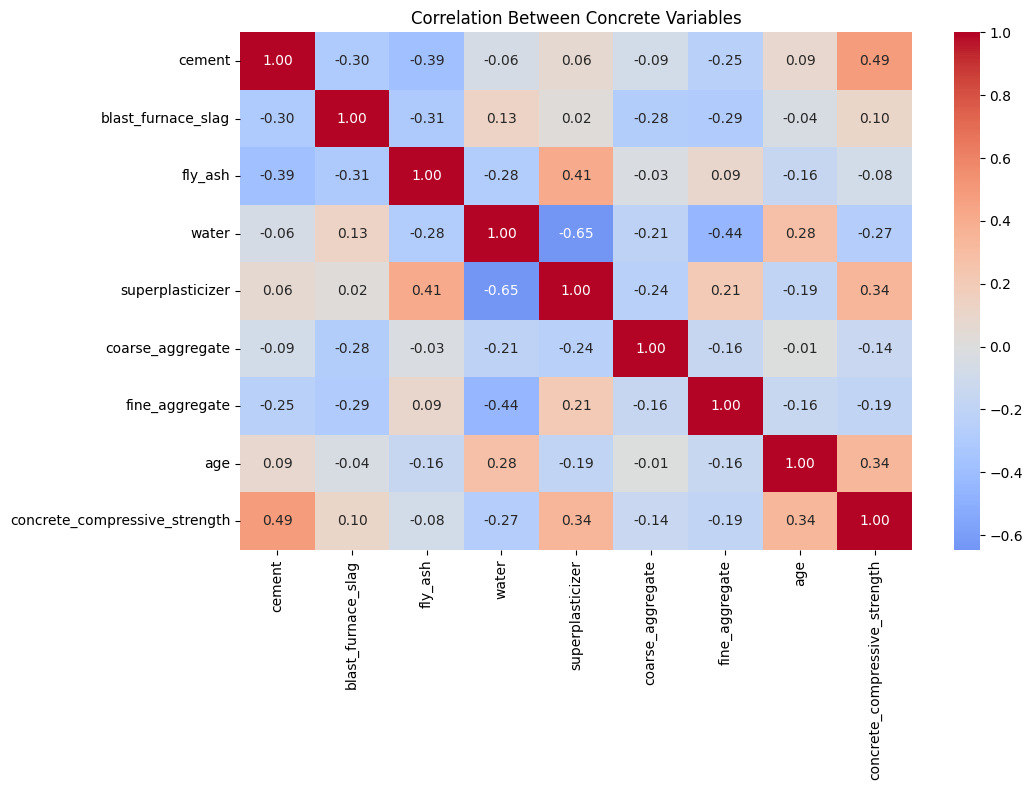

<Figure size 640x480 with 0 Axes>

In [35]:
correlation_matrix = df_concrete.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Concrete Variables")
plt.tight_layout()
plt.show()
plt.savefig(   "../plots/concrete_variable_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight")

### Correlation Analysis

Cement has the strongest positive linear relationship with concrete compressive strength (`r = 0.49`). Curing age and superplasticizer also show moderate positive correlations with strength (`r = 0.34` for both), while water has the strongest negative correlation with the target (`r = -0.27`).

The remaining ingredients show relatively weak individual linear relationships with compressive strength. However, this does not mean they are unimportant, because their effects may be nonlinear or may depend on interactions with other mixture components.

Several predictor variables are also correlated with one another. The strongest example is the negative relationship between water and superplasticizer (`r = -0.65`). These relationships should be considered when interpreting linear models, while tree-based models may be better able to capture nonlinear effects and interactions.

In [36]:
correlation_matrix[
    "concrete_compressive_strength"
].sort_values(ascending=False)

concrete_compressive_strength    1.000000
cement                           0.488283
superplasticizer                 0.344209
age                              0.337367
blast_furnace_slag               0.103374
fly_ash                         -0.080648
coarse_aggregate                -0.144717
fine_aggregate                  -0.186448
water                           -0.269624
Name: concrete_compressive_strength, dtype: float64

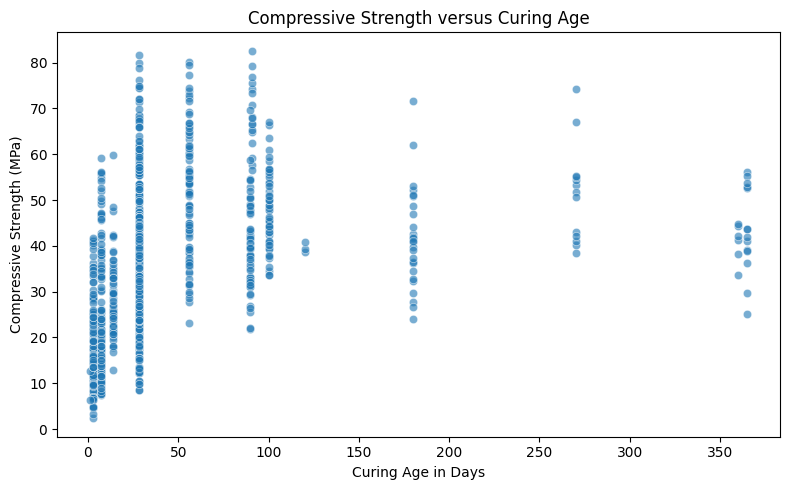

<Figure size 640x480 with 0 Axes>

In [37]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_concrete,
    x="age",
    y="concrete_compressive_strength",
    alpha=0.6
)

plt.title("Compressive Strength versus Curing Age")
plt.xlabel("Curing Age in Days")
plt.ylabel("Compressive Strength (MPa)")
plt.tight_layout()
plt.show()
plt.savefig( "../plots/compressive_strength_vs_curing_age.png",
    dpi=300,
    bbox_inches="tight")

### Curing Age and Compressive Strength

Concrete compressive strength generally increases with curing age, although the relationship is not strictly linear. The vertical clusters occur because measurements were taken at common testing ages, such as 7, 28, 56, 90, 180, and 365 days.

There is substantial variation in strength at the same curing age, particularly around 28 and 90 days. This indicates that curing age is important, but the concrete mixture composition also has a major influence on the final strength. The relationship may therefore be better captured by a nonlinear model than by a simple linear regression alone.

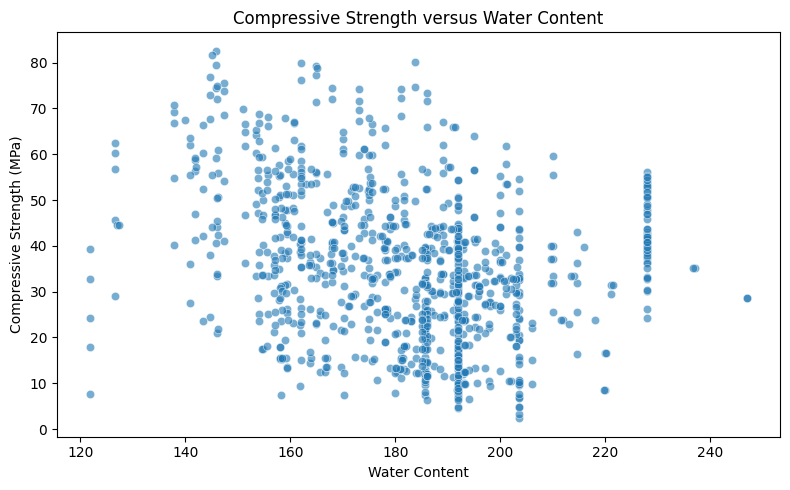

<Figure size 640x480 with 0 Axes>

In [38]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_concrete,
    x="water",
    y="concrete_compressive_strength",
    alpha=0.6
)

plt.title("Compressive Strength versus Water Content")
plt.xlabel("Water Content")
plt.ylabel("Compressive Strength (MPa)")
plt.tight_layout()
plt.show()
plt.savefig( "../plots/compressive_strength_vs_water_content.png",
    dpi=300,
    bbox_inches="tight")

### Water Content and Compressive Strength

The scatter plot shows a weak-to-moderate negative relationship between water content and concrete compressive strength, consistent with the correlation coefficient of approximately `-0.27`. Higher-strength observations are more common at lower water contents, while mixtures with greater water content tend to produce lower compressive strengths.

However, the wide spread of strength values at similar water levels shows that water content alone cannot explain concrete performance. Strength also depends on factors such as binder composition, curing age, and the proportions of the other ingredients. A water-to-binder ratio may therefore be more informative than water content by itself during feature engineering.

In [39]:
from pathlib import Path

processed_path = Path("../processed_data")


df_concrete.to_csv(
    processed_path / "concrete_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

Cleaned dataset saved.
